# Minh họa năm cấu hình phân cụm sâu

AE + K-means, DEC, IDEC, DCN và IDEC + BRB. Dữ liệu Digits kèm sẵn. Code NumPy minh họa cơ chế; cấu hình khác với bài báo gốc.

Mở notebook sau khi giải nén và cài requirements. Có thể chạy bằng Jupyter trên máy hoặc tải toàn bộ ZIP lên Colab rồi giải nén. Trong Colab, giải nén vào `/content` trước khi chạy các ô bên dưới.

In [1]:
from pathlib import Path
import sys
import subprocess
from datetime import datetime

# Tìm thư mục dự án từ vị trí notebook hoặc vị trí giải nén.
candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parents[1], Path("/content/Deep_Clustering_Demo")]
ROOT = next((p for p in candidates if (p / "run_demo.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Hãy giải nén thư mục Deep_Clustering_Demo rồi sửa ROOT cho đúng vị trí.")
print(ROOT)

F:\ThacSi\Data Mining\Survey\Deep_Clustering_Demo


## Cài thư viện nếu môi trường chưa có
Ô sau cần mạng để cài thư viện. Việc chạy thí nghiệm không cần mạng sau khi đã cài xong.

In [2]:
import sys, numpy, pandas
print(sys.version)
print('numpy', numpy.__version__, 'pandas', pandas.__version__)
# Môi trường đã có thư viện; xem kết quả đã kiểm chứng.

3.14.2 (tags/v3.14.2:df79316, Dec  5 2025, 17:18:21) [MSC v.1944 64 bit (AMD64)]
numpy 2.5.1 pandas 2.3.3


X: (1797, 64) y: (1797,) range: 0.0 1.0


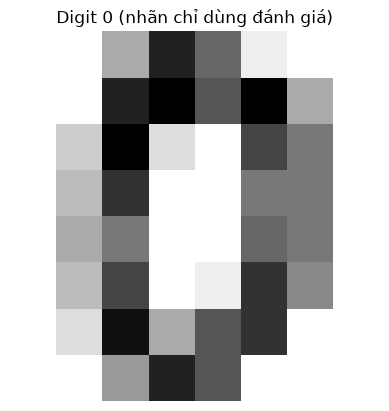

In [3]:
import numpy as np
import matplotlib.pyplot as plt

bundle = np.load(ROOT / "data" / "digits_1797.npz", allow_pickle=False)
X, y = bundle["X"], bundle["y"]
print("X:", X.shape, "y:", y.shape, "range:", X.min(), X.max())
plt.imshow(X[0].reshape(8, 8), cmap="gray_r")
plt.title(f"Digit {y[0]} (nhãn chỉ dùng đánh giá)")
plt.axis("off");

## Xem lần chạy đã kiểm chứng hoặc chạy mới
Mặc định đọc kết quả 25 lượt đã chạy trên máy này. Đổi RUN_NEW_EXPERIMENT thành True để chạy mới. Mỗi seed huấn luyện lại autoencoder; các phương pháp cùng seed dùng chung điểm khởi đầu. Đổi SEEDS thành [0] nếu muốn thử nhanh.

In [4]:
SEEDS = [0, 1, 2, 3, 4]
RUN_NEW_EXPERIMENT = False
if RUN_NEW_EXPERIMENT:
    OUT = ROOT / "results" / ("legacy_notebook_" + datetime.now().strftime("%Y%m%d_%H%M%S"))
    command = [sys.executable, str(ROOT / "run_demo.py"), "--methods", "AE_KMeans", "DEC", "IDEC", "DCN", "IDEC_BRB", "--output", str(OUT), "--seeds", *map(str, SEEDS)]
    subprocess.check_call(command, cwd=ROOT)
    subprocess.check_call([sys.executable, str(ROOT / 'checks' / 'verify_experiment.py'), '--results', str(OUT)], cwd=ROOT)
    subprocess.check_call([sys.executable, str(ROOT / 'scripts/summarize_survey.py'), '--output', str(OUT / 'survey_counts.json')], cwd=ROOT)
else:
    OUT = ROOT / "archive/results_verified_20261012"
    assert (OUT / "summary.csv").exists(), "Chưa có kết quả: đổi RUN_NEW_EXPERIMENT thành True."
print(OUT)

F:\ThacSi\Data Mining\Survey\Deep_Clustering_Demo\results_verified_20261012


In [5]:
import pandas as pd
summary = pd.read_csv(OUT / "summary.csv")
summary

,method,n_runs,acc_mean,acc_std,nmi_mean,nmi_std,ari_mean,ari_std,standalone_seconds_mean,standalone_seconds_std,pairwise_ari_mean,pairwise_ari_std,n_pairs
0,AE_KMeans,5,0.692599,0.064282,0.654438,0.037495,0.549760,0.051791,2.680312,0.623235,0.534062,0.056713,10
1,DEC,5,0.743239,0.083448,0.736456,0.048751,0.627024,0.080372,4.079906,0.575290,0.650428,0.063057,10
2,IDEC,5,0.745019,0.080689,0.735330,0.046588,0.624852,0.080210,4.106621,0.623793,0.661550,0.060632,10
3,DCN,5,0.656539,0.049222,0.623915,0.050437,0.511905,0.054501,3.981069,0.602370,0.536248,0.036888,10
4,IDEC_BRB,5,0.742237,0.063671,0.714955,0.032522,0.618164,0.054725,4.100925,0.570615,0.644867,0.047181,10


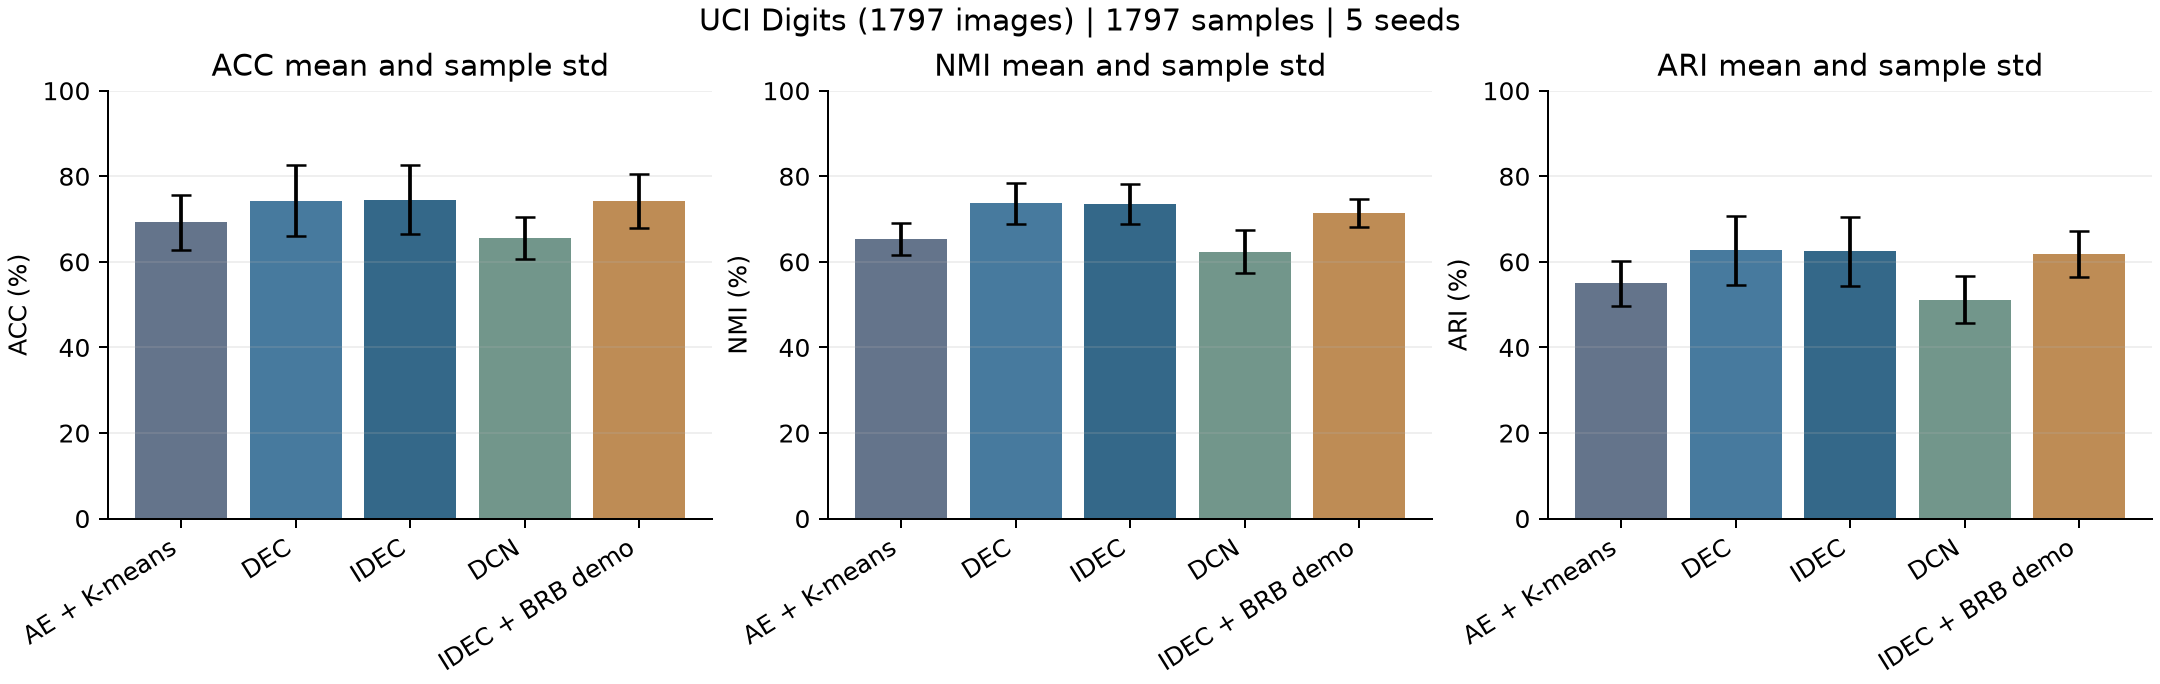

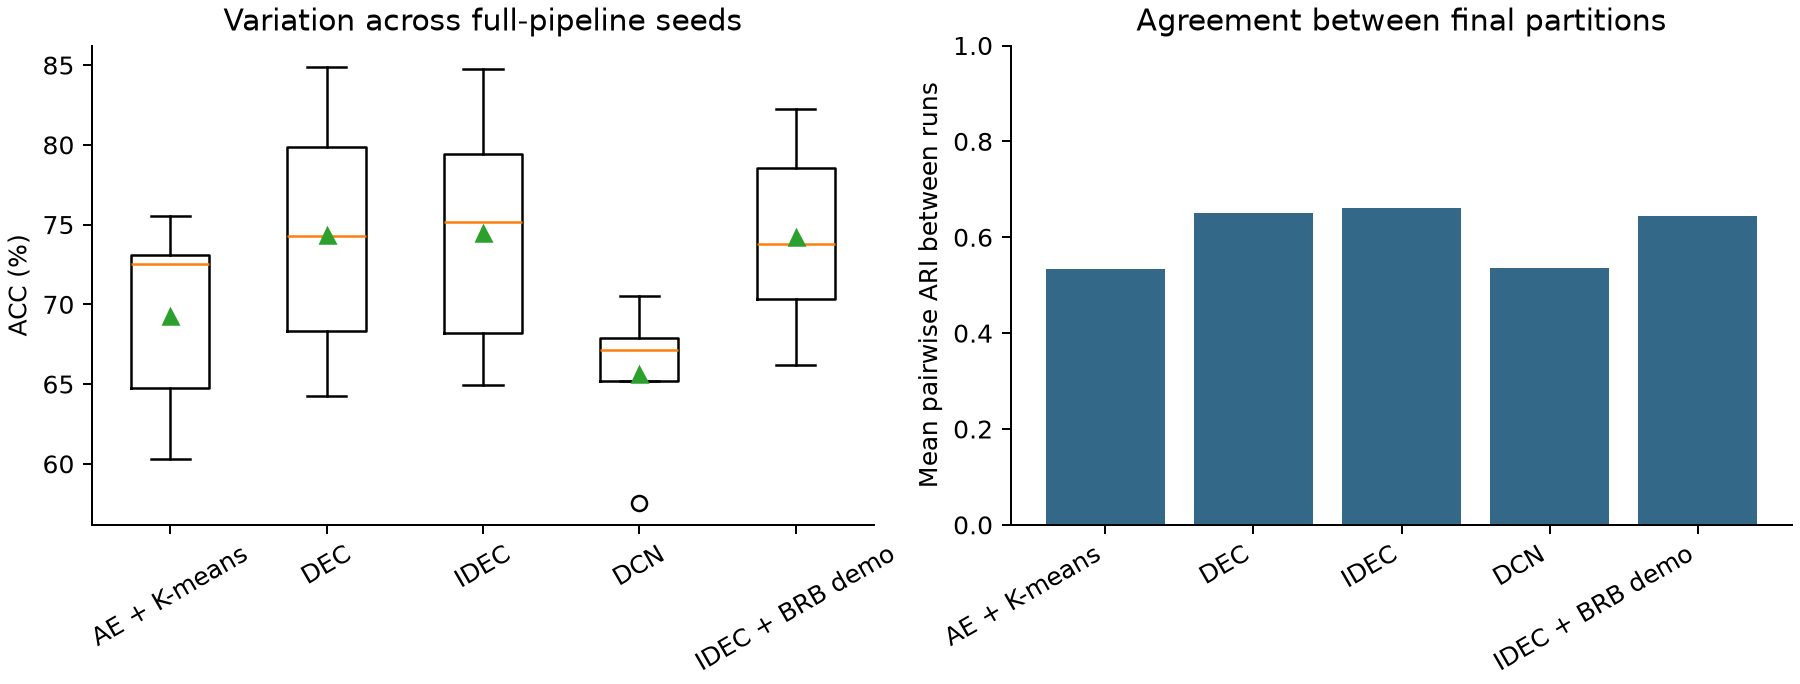

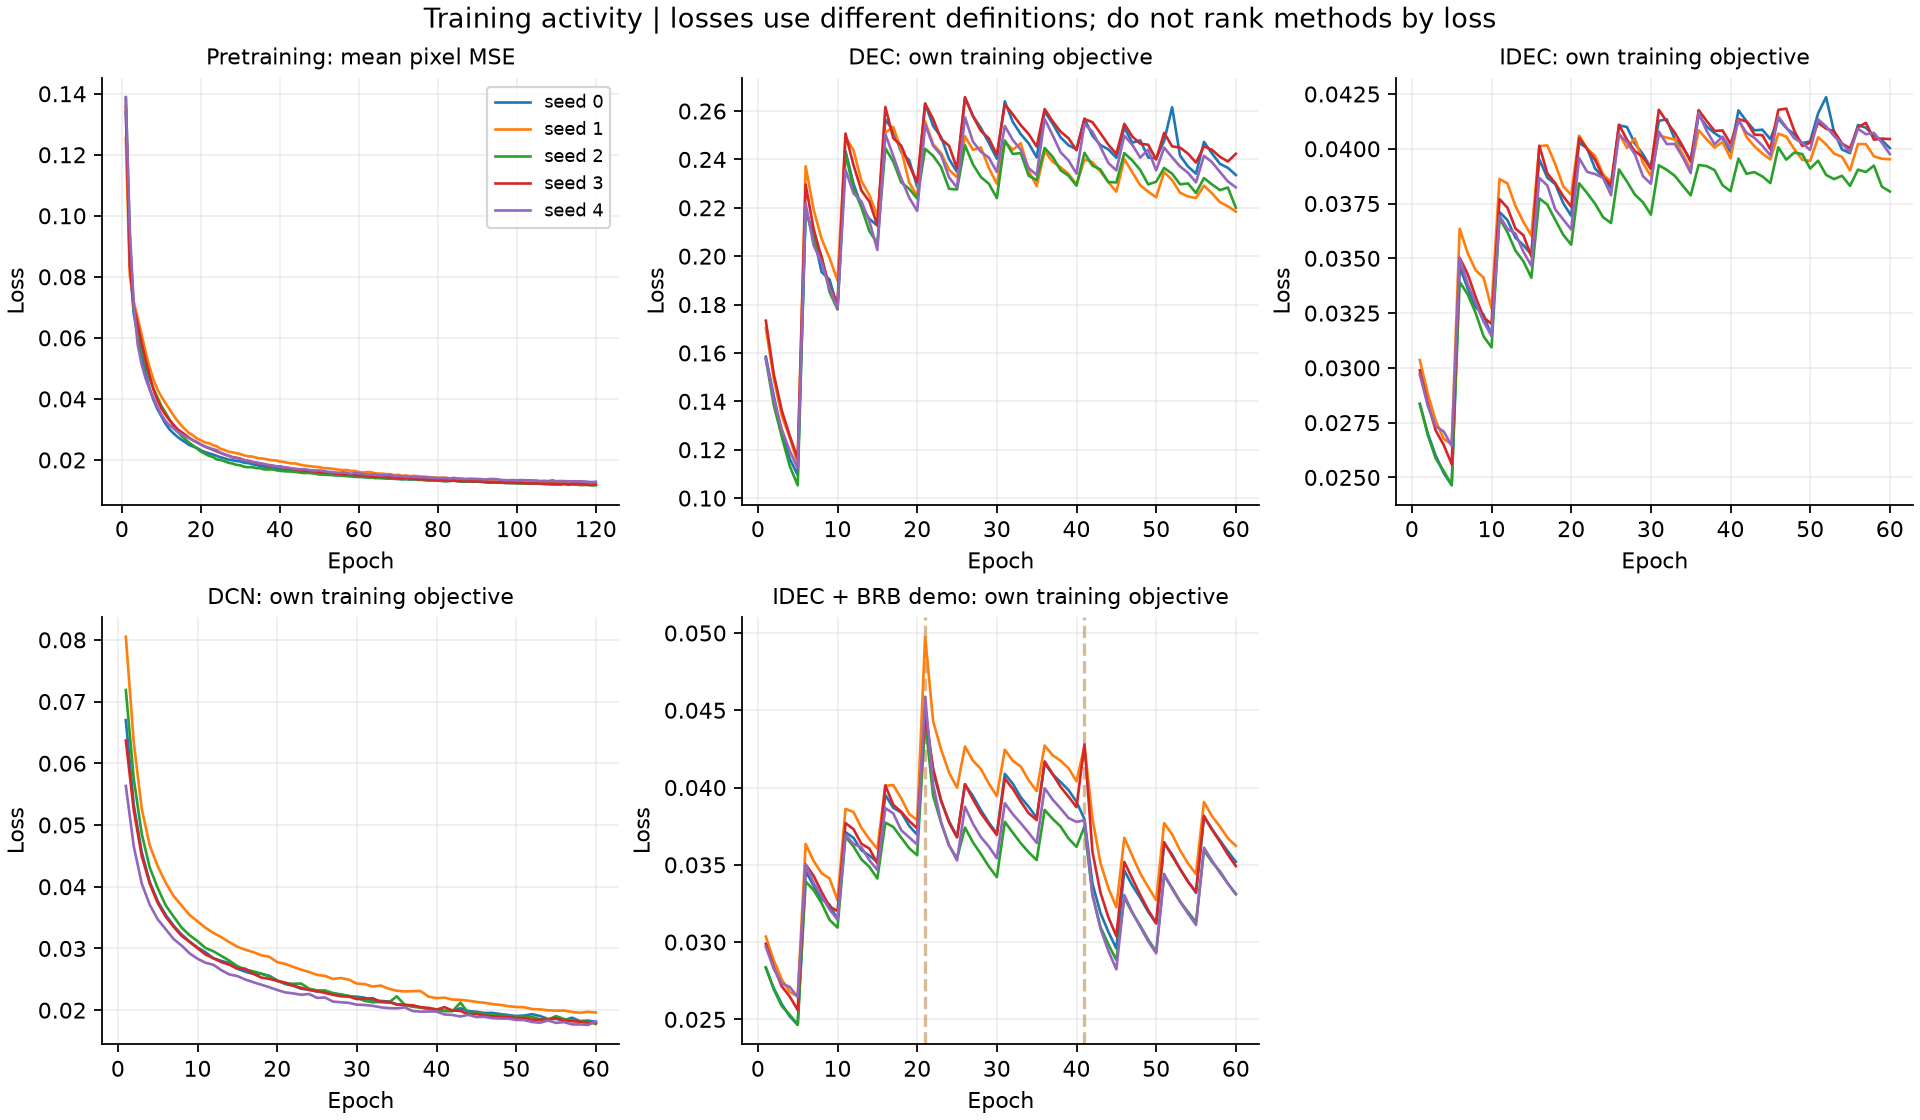

In [6]:
from IPython.display import Image, display
display(Image(filename=str(OUT / "performance.png")))
display(Image(filename=str(OUT / "stability.png")))
display(Image(filename=str(OUT / "loss_curves.png")))

## Xem cơ chế Q và P trên cùng dữ liệu
Q là soft assignment Student-t sau pretrain và K-means. P tăng trọng số assignment tự tin và hiệu chỉnh tần suất cụm, tính từ toàn bộ X. Mỗi hàng Q/P có tổng bằng 1; không dùng y. Trong DEC/IDEC, P được giữ cố định trong 5 epoch rồi cập nhật, nên loss có thể tạo răng cưa và thay đổi giá trị khi target đổi.

In [7]:
sys.path.insert(0, str(ROOT))
from src.models import Autoencoder, assignments, target_distribution
import json
config = json.loads((OUT / 'config.json').read_text(encoding='utf-8'))
seed = config['seeds'][0]
model = Autoencoder(X.shape[1], config['latent_dim'], seed)
with np.load(OUT / 'models' / f'pretrain_seed{seed}.npz') as saved:
    model.params = {key: saved[key].copy() for key in model.params}
with np.load(OUT / 'models' / f'initialization_seed{seed}.npz') as saved:
    centers = saved['centers'].copy()
Q = assignments(model.encode(X), centers)
P = target_distribution(Q)
np.testing.assert_allclose(Q.sum(axis=1), 1)
np.testing.assert_allclose(P.sum(axis=1), 1)
display(pd.DataFrame(Q[:5]).round(3))
display(pd.DataFrame(P[:5]).round(3))

,0,1,2,3,4,5,6,7,8,9
0,0.106,0.043,0.070,0.031,0.489,0.049,0.039,0.071,0.045,0.057
1,0.045,0.152,0.087,0.298,0.036,0.076,0.094,0.079,0.073,0.061
2,0.053,0.205,0.103,0.144,0.063,0.082,0.106,0.078,0.102,0.063
3,0.086,0.088,0.311,0.077,0.063,0.069,0.107,0.060,0.057,0.082
4,0.117,0.074,0.086,0.065,0.141,0.074,0.045,0.240,0.093,0.064


,0,1,2,3,4,5,6,7,8,9
0,0.046,0.006,0.016,0.004,0.871,0.009,0.007,0.020,0.008,0.013
1,0.014,0.133,0.042,0.596,0.008,0.039,0.066,0.041,0.035,0.026
2,0.026,0.321,0.079,0.184,0.033,0.061,0.112,0.054,0.092,0.037
3,0.057,0.049,0.593,0.044,0.027,0.035,0.095,0.026,0.024,0.050
4,0.115,0.038,0.049,0.034,0.146,0.044,0.018,0.454,0.069,0.034


In [8]:
import json
print(json.dumps(json.loads((OUT / 'verification.json').read_text(encoding='utf-8')), ensure_ascii=False, indent=2))
display(pd.read_csv(ROOT / 'data' / 'paper_tracker.csv').fillna(''))

{
  "status": "passed",
  "runs_verified": 25,
  "dataset_samples": 1797,
  "same_training_data_all_methods": true,
  "sha256_training_X": "23a53393488b04f92efc45ebc92767e2dcfdf206ba37a928f497d261e42267d2",
  "metrics_recomputed_from_predictions": true,
  "predictions_recomputed_from_saved_models": true,
  "max_metric_error": 5.551115123125783e-17,
  "seed_pairs_verified": 50,
  "summary_and_sample_std_verified": true,
  "brb_reset_schedule_verified": true,
  "original_authors_code": "not executed; independent NumPy demonstration",
  "reference_comparison": {
    "matched_runs": 25,
    "max_absolute_metric_difference": {
      "acc": 0.0,
      "nmi": 0.0,
      "ari": 0.0
    },
    "note": "Library versions and CPU differ; timing accounting now includes initial KMeans."
  }
}


,paper_id,method,title,year,venue,publication_type,paper_url,code_url,code_public,code_smoke_tested,...,code_availability_verified,code_availability_source,code_provenance,datasets,datasets_source,dataset_scope_verified,original_dataset_download_verified,quartile_verified,verified_on,quartile_verification_note
0,P01,DEC,Unsupervised Deep Embedding for Clustering Ana...,2016,ICML,conference,https://proceedings.mlr.press/v48/xieb16.html,https://github.com/piiswrong/dec,yes,no,...,yes,https://github.com/piiswrong/dec,author,MNIST (70000); STL-10 labeled (13000; HOG+colo...,https://proceedings.mlr.press/v48/xieb16.pdf,yes,no,no,2026-10-12,Not applicable: conference paper
1,P02,IDEC,Improved Deep Embedded Clustering with Local S...,2017,IJCAI,conference,https://www.ijcai.org/proceedings/2017/243,https://github.com/XifengGuo/IDEC,yes,no,...,yes,https://github.com/XifengGuo/IDEC,author,MNIST (70000); USPS (9298); REUTERS-10K (10000),https://www.ijcai.org/proceedings/2017/0243.pdf,yes,no,no,2026-10-12,Not applicable: conference paper
2,P03,DCN,Towards K-means-friendly Spaces Simultaneous D...,2017,ICML,conference,https://proceedings.mlr.press/v70/yang17b.html,https://github.com/boyangumn/DCN-New,yes,no,...,yes,https://github.com/boyangumn/DCN-New,author_updated_repository,RCV1-v2 (365968 single-label documents in 20 t...,https://proceedings.mlr.press/v70/yang17b/yang...,yes,no,no,2026-10-12,Not applicable: conference paper
3,P04,DEC-DA,Deep Embedded Clustering with Data Augmentation,2018,ACML,conference,https://proceedings.mlr.press/v95/guo18b.html,https://github.com/XifengGuo/DEC-DA,yes,no,...,yes,https://github.com/XifengGuo/DEC-DA,author,MNIST; MNIST-test; USPS; Fashion-MNIST,https://github.com/XifengGuo/DEC-DA#highlights,yes,no,no,2026-10-12,Not applicable: conference paper
4,P05,SCAN,SCAN Learning to Classify Images without Labels,2020,ECCV,conference,https://www.ecva.net/papers/eccv_2020/papers_E...,https://github.com/wvangansbeke/Unsupervised-C...,yes,no,...,yes,https://github.com/wvangansbeke/Unsupervised-C...,author,CIFAR10; CIFAR100-20; STL10; ImageNet (includi...,https://github.com/wvangansbeke/Unsupervised-C...,yes,no,no,2026-10-12,Not applicable: conference paper
5,P06,CC,Contrastive Clustering,2021,AAAI,conference,https://doi.org/10.1609/aaai.v35i10.17037,https://github.com/Yunfan-Li/Contrastive-Clust...,yes,no,...,yes,https://github.com/Yunfan-Li/Contrastive-Clust...,author,CIFAR-10; CIFAR-100; STL-10; Tiny-ImageNet; Im...,https://github.com/Yunfan-Li/Contrastive-Clust...,yes,no,no,2026-10-12,Not applicable: conference paper
6,P07,DECRA,Deep Embedding Clustering Based on Residual Au...,2024,Neural Processing Letters,journal,https://doi.org/10.1007/s11063-024-11586-0,https://github.com/lml-mengli/DECRA,yes,no,...,yes,https://github.com/lml-mengli/DECRA; https://l...,author,MNIST (70000); Fashion-MNIST (70000); REUTERS-...,https://link.springer.com/article/10.1007/s110...,yes,no,no,2026-10-12,Unknown: publisher verifies journal identity b...
7,P08,BRB,Breaking the Reclustering Barrier in Centroid-...,2025,ICLR,conference,https://proceedings.iclr.cc/paper_files/paper/...,https://github.com/Probabilistic-and-Interacti...,yes,no,...,yes,https://github.com/Probabilistic-and-Interacti...,author,Repo-supported: MNIST; FashionMNIST; KMNIST; U...,https://github.com/Probabilistic-and-Interacti...,yes,no,no,2026-10-12,Not applicable: conference paper


## Cách hiểu kết quả
ACC, NMI, ARI trong CSV nằm trên thang 0–1. Các biểu đồ hiệu năng đổi sang phần trăm. Pairwise ARI so sánh hai kết quả phân cụm trên cùng mẫu, không dùng nhãn thật. Năm seed tạo ra 10 cặp cho mỗi phương pháp; các cặp có dùng chung lần chạy nên không phải 10 quan sát độc lập.

Kết quả của bộ Digits nhỏ chưa xác định phương pháp tốt nhất trên MNIST hoặc toàn bộ deep clustering. Thư mục results chứa kết quả tham chiếu đã chạy kèm theo gói.